---
title: Vegetation, land use and Google's Earth Engine API

authors:
  - name: "Alejandro Fontal"
    email: "alejandro.fontal.92@gmail.com"
    url: "https://alfontal.dev"
    orcid: 0000-0003-1138-2158


description: Exploring vegetation and land-use patterns across Asia with Google Earth Engine.
date: 2023-05-16
categories:
  - Remote Sensing
  - Earth Engine
  - GIS
  - Land Use
author: Alejandro Fontal
image: featured_ndvi.png
card: featured_ndvi.webp
format:
  html:
    warning: false
    smooth-scroll: true
    toc: true
    number-sections: false

---


#### Preamble {-}

<details>
<summary>Show code imports and presets</summary>

<br>
In this section we load the necessary libraries and set the global parameters for the
notebook. It's irrelevant for the narrative of the analysis but essential for the 
reproducibility of the results.

##### Imports {-}

In [ ]:
import ee
import wxee
import numpy as np
import pandas as pd
import xarray as xr
import plotnine as p9
import geopandas as gpd
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import matplotlib.path as mpath
import matplotlib.ticker as mtick
import cartopy.feature as cfeature


from tqdm import tqdm
from shapely.geometry import Polygon
from mizani.breaks import date_breaks
from matplotlib_inline.backend_inline import set_matplotlib_formats
from mizani.formatters import custom_format, date_format, percent_format


##### Pre-sets {-}

In [8]:
# Matplotlib settings
plt.rcParams['font.family'] = 'Georgia'
plt.rcParams['svg.fonttype'] = 'none'
set_matplotlib_formats('retina')
plt.rcParams['figure.dpi'] = 300
# Plotnine settings (for figures)

p9.options.set_option('base_family', 'Georgia')

p9.theme_set(
    p9.theme_bw()
    + p9.theme(panel_grid=p9.element_blank(),
               legend_background=p9.element_blank(),
               panel_grid_major=p9.element_line(size=.5, linetype='dashed',
                                                alpha=.15, color='black'),
               dpi=300
    )
)


## Introduction

In this notebook we are going to explore the usage of Google's Earth Engine API to
visualize changes in vegetation and land use across Asia. The goal is to build a
reproducible remote-sensing workflow that makes it easier to compare large-scale
spatial patterns over time. 

## Earth Engine API

### Authentication

The first step is to authenticate the user with the Google's Earth Engine API. This
is done by running the following code, which opens up a new window in the browser
where the user can authenticate with their Google account. The user should have previously
registered in the Earth Engine platform as a developer.

There is the option to provide only read-only access to the user's data, but in this
case we want to save the results of the analysis in the user's Google Drive, so we
need to provide full access to the user's Google account.

After the authentication step, a token is generated and stored in the user's computer.
We can now just use that token to initialize the Earth Engine API:

In [ ]:
ee.Authenticate()

In [4]:
ee.Initialize()
wxee.Initialize()

We should now be able to use the Earth Engine API to query the data we need with our
Google account.

### Data selection and wrangling with Earth Engine

We are going to use the **MOD13A2** data product, which is a 16-day composite of the
**Terra MODIS** satellite imagery. The data is available starting from 2000-02-18 for
the whole globe at a spatial resolution of 1000 m. 

Since we are interested in the vegetation dynamics in Asia, we are going to focus on
the region between 20°N - 60°N and 78°E - 165°E. We can select this region by defining
a bounding box and then filtering the data by the bounding box coordinates.

The selected region looks like this:

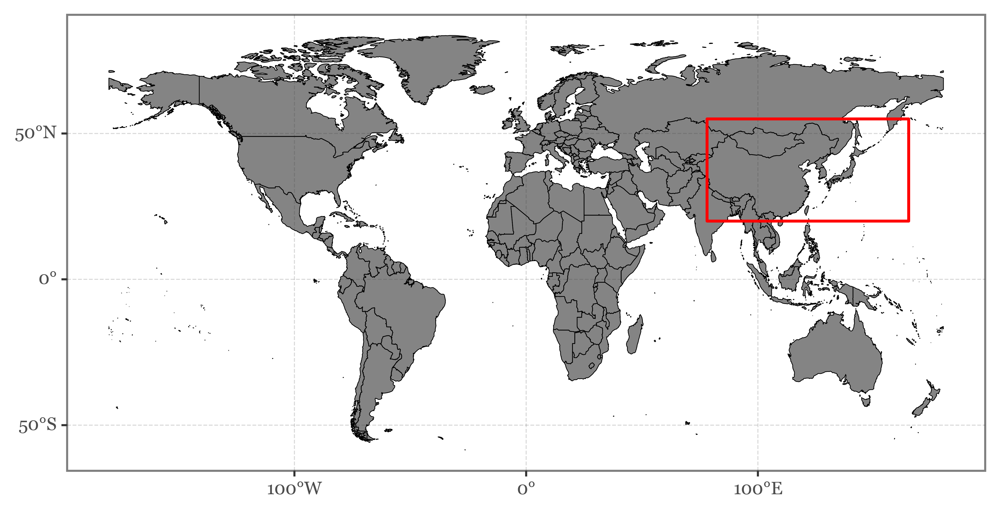

<ggplot: (276695902)>

In [ ]:
#| code-fold: true

aoi = Polygon([(78, 20), (78, 55), (165, 55), (165, 20)])
world_gdf = gpd.read_file('../data/shapefiles/ne_50m_admin_0_countries.zip')
(world_gdf
 .query('NAME != "Antarctica"')
 .pipe(lambda dd: p9.ggplot(dd) 
            + p9.geom_map(color='black', size=.2, alpha=.6) 
            + p9.scale_x_continuous(breaks=[-100, 0, 100],
                                    labels=['100°W', '0°', '100°E'])
            + p9.scale_y_continuous(breaks=[-50, 0, 50],
                                    labels=['50°S', '0°', '50°N'])
            + p9.theme(figure_size=(8, 4))
            + p9.annotate('rect', xmin=78, xmax=165, ymin=20, ymax=55,
                          color='red', size=.8, alpha=0)
            )
)

Zooming in:

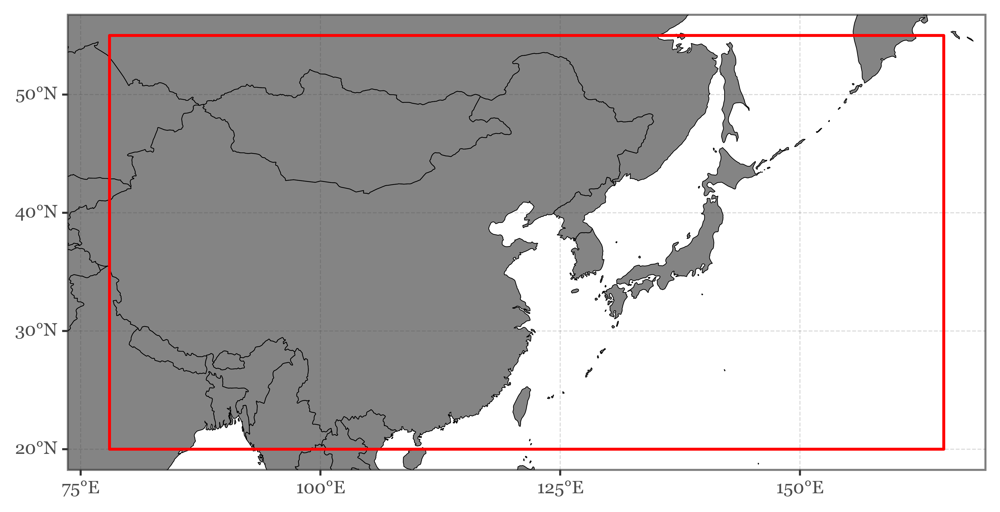

<ggplot: (712945295)>

In [13]:
#| code-fold: true
(world_gdf
 .pipe(lambda dd: p9.ggplot(dd) 
    + p9.geom_map(color='black', size=.2, alpha=.6) 
    + p9.scale_x_continuous(labels=custom_format('{:0g}°E'),
                            limits=(78, 165))
    + p9.scale_y_continuous(labels=custom_format('{:0g}°N'),
                            limits=(20, 55))
    + p9.theme(figure_size=(8, 4))
    + p9.annotate('rect', xmin=78, xmax=165, ymin=20, ymax=55,
                  color='red', size=.8, alpha=0)
            )
)

In total, the area defined by the bounding box contains surface pixels from 20 different
countries:

In [137]:
#| code-fold: true

for country in world_gdf.loc[world_gdf.geometry.intersects(aoi)].ADMIN.unique():
    print(country)

Vietnam
Thailand
Taiwan
South Korea
Russia
Philippines
North Korea
Nepal
Mongolia
Laos
Kyrgyzstan
Kazakhstan
Japan
India
China
Macao S.A.R
Hong Kong S.A.R.
Myanmar
Bhutan
Bangladesh


We'll keep the ISO codes of those countries in a list for later use in case 
we need to filter the data by country later on. 

In [14]:
iso_codes = world_gdf.loc[world_gdf.geometry.intersects(aoi)].ADM0_ISO.unique()

Let's now start to interact with the Earth Engine API. We first need to select the 
actual data product we want to use. In this case, we are going to use the **MOD13A2**
and we'll select the **NDVI** band, which is the Normalized Difference Vegetation Index:

In [15]:
modis_ndvi = ee.ImageCollection("MODIS/006/MOD13A2").select("NDVI")

We can now filter by bounds to select the pixels within the bounding box we defined
before (previous transformation to the Earth Engine coordinate system):

In [247]:
aoi_bounds = ee.Geometry.Rectangle(aoi.bounds)


In [248]:
aoi_bounds = ee.Geometry.Rectangle(aoi.bounds)
asia_ndvi = modis_ndvi.filterBounds(aoi_bounds)

### Image collection visualizations

To make sure we are selecting the correct data, we can plot an animation of the time 
series of the NDVI values for a single year, such as 2019. The data is available for 
every 16 days, so in total we will have 22 images for the year 2019:

In [249]:
asia_ndvi_2019 = asia_ndvi.filterDate('2019-01-01', '2019-12-31')

If we now generate a visualization (defining some parameters previously),
we get a link that points to the following:

In [250]:
#| code-fold: true
#| hide-output: true

vis_params = {
    'min': 0.0,
    'max': 9000.0,
    'palette': [
        'FFFFFF', 'CE7E45', 'DF923D', 'F1B555', 'FCD163', '99B718', '74A901',
        '66A000', '529400', '3E8601', '207401', '056201', '004C00', '023B01',
        '012E01', '011D01', '011301'
    ],
}

gif_params = {
    'region': aoi_bounds,
    'dimensions': 1000,
    'framesPerSecond': 1,
    'crs': 'EPSG:3857',
}

asia_ndvi_2019.map(lambda dd: dd.visualize(**vis_params)).getVideoThumbURL(gif_params)

'https://earthengine-highvolume.googleapis.com/v1alpha/projects/earthengine-legacy/videoThumbnails/3b3324b689c895e28bd97836a74a9b89-2d7e485f3020916801793e5949a87484:getPixels'

![NDVI images for the year 2019](images/asia_2019_ndvi.gif)

We can also use the API to directly run expensive computations which would take a long time on a local machinein Google's servers. 

For example, we can compute the median NDVI per year in each pixel of the bounding box and generate a new visualization:

In [202]:
gif_params['region'] = ne_china_bounds
seasonal_medians.filterBounds(ne_china_bounds).map(lambda dd: dd.visualize(**vis_params)).getVideoThumbURL(gif_params)

'https://earthengine-highvolume.googleapis.com/v1alpha/projects/earthengine-legacy/videoThumbnails/e5b49b61cd8def840ab5e775fda66e5b-a257082415c81470ccc8e58435609072:getPixels'

In [27]:
#| code-fold: true

yearly_medians = []
for year in range(2001, 2022):
    yearly_median = asia_ndvi.filterDate(ee.Date.fromYMD(year, 1, 1),
                                         ee.Date.fromYMD(year + 1, 1, 1))
    yearly_medians.append(yearly_median
                          .median()
                          .set("system:time_start", ee.Date.fromYMD(year, 1, 1)))

yearly_medians = ee.ImageCollection(yearly_medians)
yearly_medians.map(lambda dd: dd.visualize(**vis_params)).getVideoThumbURL(gif_params)

'https://earthengine-highvolume.googleapis.com/v1alpha/projects/earthengine-legacy/videoThumbnails/2bf609ce1c11322209e3fa0097ac6407-36e1808ec3e375c536e203c8b0c116b4:getPixels'

![Median NDVI image per year (2000-2023)](images/asia_median_ndvi.gif)

Another thing we might be more interested in doing is to observe the median seasonal
cycle of the NDVI values for each pixel in the whole period since 2000.

Since the NDVI values are 16 day composites and don't match exactly with the yearly 
calendar, we will first assign each of the 22/23 images that each year has to a 16-day
period of the year. We can then compute the median NDVI value per period and pixel 
and perform further computations with the data.

If we do that, the resulting image is similar to the one we obtained for 2019 (as it
contained a full seasonal cycle) but more smoothed out:

In [201]:
#| code-fold: true

def add_period_of_year(image):
    """Add day of year to image."""
    date = ee.Date(image.get('system:time_start'))
    day_of_year = date.getRelative('day', 'year')
    period_of_year = day_of_year.floor().divide(16).add(1)
    return image.set('period_of_year', period_of_year)

asia_ndvi = asia_ndvi.map(add_period_of_year)
seasonal_medians = []
for period in range(1, (366 // 16 + 1)):
    period_median = asia_ndvi.filter(ee.Filter.eq('period_of_year', period))
    seasonal_medians.append(period_median.median().set({'period': period}))

seasonal_medians = ee.ImageCollection(seasonal_medians)
(seasonal_medians
 .map(lambda dd: dd.visualize(**vis_params))
 .getVideoThumbURL(gif_params)
)

![Median NDVI per biweekly period of the year (2000-2023)](images/asia_seasonal_medians.gif)

### Computing statistics and measuring changes

While the previous visualizations are useful to get a general idea of the data, we
might be more interested in computing some statistics and measuring changes in the
vegetation over time that can be used in further analysis.

Let's take a look at how to do that while offseting the computation to Google's servers.

#### NDVI change over time

Let's define a region of interex within the bounding box we defined before. We'll
select the area in northeastern China (with areas of Mongolia and Russia) that is
one of the main sources of westerly winds that reach Japan:

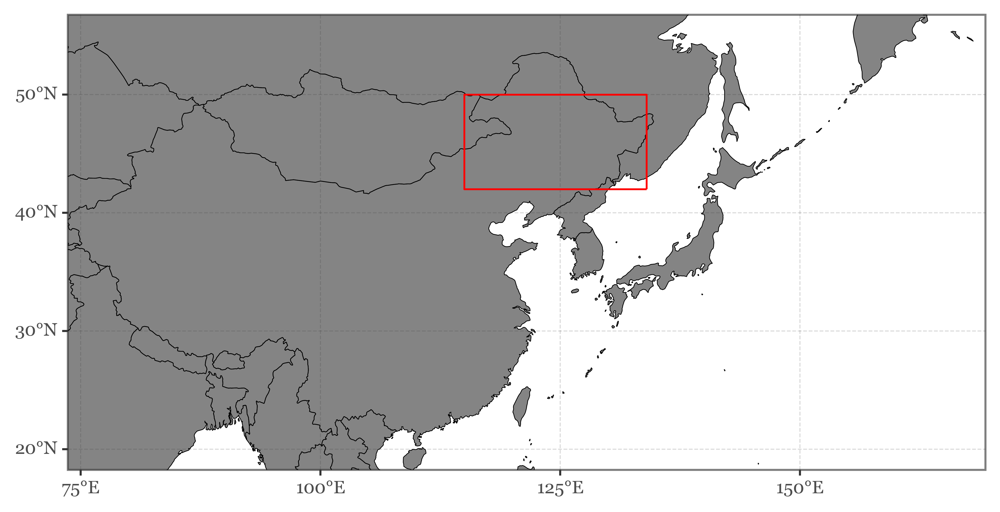

<ggplot: (706298193)>

In [251]:
#| code-fold: true

ne_china = Polygon([
        (134, 42),
        (134, 50),
        (115, 50),
        (115, 42)
        ])

ne_china_bounds = ee.Geometry.Rectangle(ne_china.bounds)

(world_gdf
 .pipe(lambda dd: p9.ggplot(dd) 
    + p9.geom_map(color='black', size=.2, alpha=.6) 
    + p9.scale_x_continuous(labels=custom_format('{:0g}°E'),
                            limits=(78, 165))
    + p9.scale_y_continuous(labels=custom_format('{:0g}°N'),
                            limits=(20, 55))
    + p9.theme(figure_size=(8, 4))
    + p9.geom_map(data=gpd.GeoDataFrame(dict(geometry=[ne_china])),
                  fill=None, color='red')
 )
)

We'll compute the mean NDVI value for the whole region for each of the periods, and 
store the results in a local list:

In [161]:
def compute_mean_ndvi(image, out_list):
    mean_ndvi = image.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=ne_china_bounds,
        scale=500  # MODIS resolution is 500m
    ).get("NDVI")

    return ee.List(out_list).add(ee.Dictionary({
        "system:index": image.get("system:index"),
        "system:time_start": image.get("system:time_start"),
        "system:time_end": image.get("system:time_end"),
        "mean_ndvi": mean_ndvi
    }))

In [ ]:
start_date = '2010-06-21'
end_date = '2021-12-31'
date_range = pd.date_range(start_date, end_date, freq='16D')
# series = defaultdict(list)
ne_china_ndvi = asia_ndvi.filterBounds(ne_china_bounds)
for start, end in tqdm(zip(date_range[:-1], date_range[1:]),
                       total=len(date_range) - 1):    
    filtered = (ne_china_ndvi
        .filterDate(start.strftime("%Y-%m-%d"),  end.strftime("%Y-%m-%d"))
        .first()
    )
    mean_ndvi = (filtered
        .reduceRegion(ee.Reducer.mean(), ne_china_bounds, 500)
        .get("NDVI")
        .getInfo()
    )
    series['mean_ndvi'].append(mean_ndvi)
    series['date'].append(start)

If we now plot the results, we can observe the clear seasonal cycle of the NDVI values:

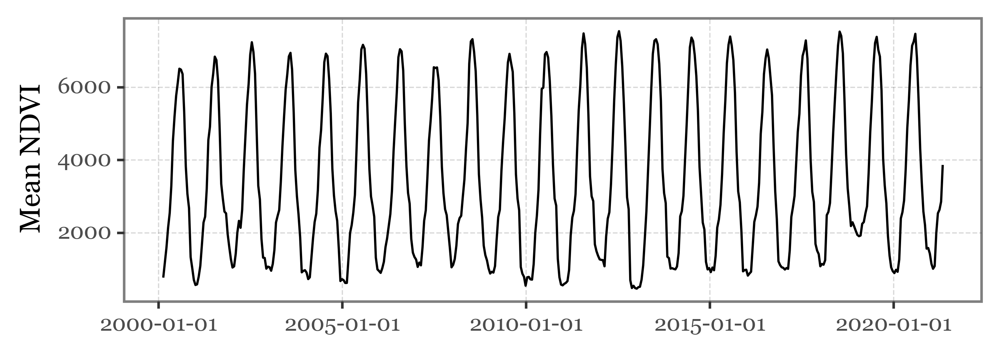

<ggplot: (706325562)>

In [245]:
#| code-fold: true

(pd.DataFrame(series)
 .pipe(lambda dd: p9.ggplot(dd)
  + p9.aes('date', 'mean_ndvi')
  + p9.geom_line()
  + p9.theme(figure_size=(6, 2))
  + p9.labs(x='', y='Mean NDVI')
 )
)

In [184]:
pd.DataFrame(series).date.max(
    
)

,mean_ndvi,date
0,772.256545,2000-02-18
1,1182.915976,2000-03-05
2,1600.821338,2000-03-21
3,2140.528870,2000-04-06
4,2542.288759,2000-04-22
...,...,...
231,2001.654737,2010-04-02
232,2475.060747,2010-04-18
233,3185.733557,2010-05-04
234,4709.294367,2010-05-20


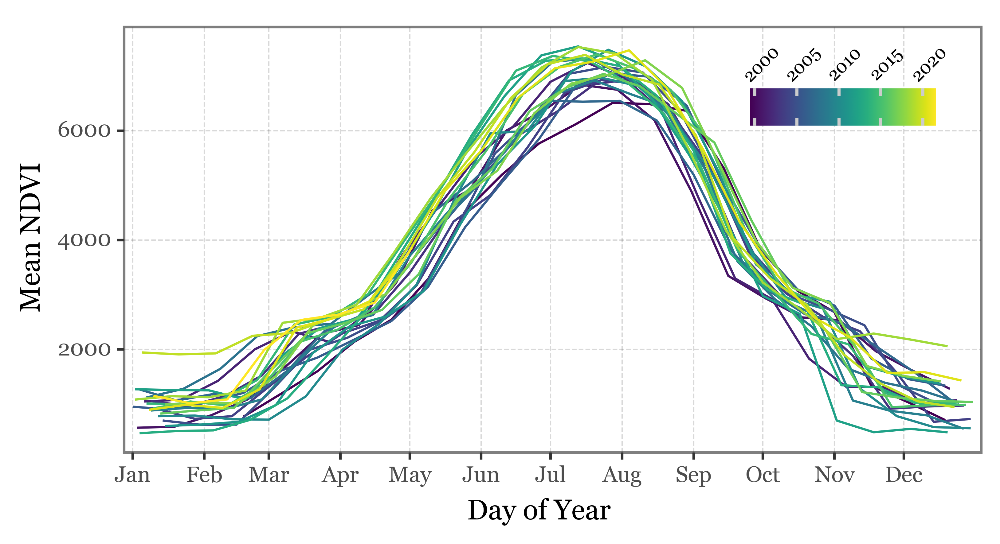

<ggplot: (705314414)>

In [187]:
#| code-fold: true

(pd.DataFrame(series)
 .assign(day_of_year=lambda dd: dd.date.dt.dayofyear)
 .assign(year=lambda dd: dd.date.dt.year)
 .pipe(lambda dd: p9.ggplot(dd)
    + p9.aes(x='day_of_year', y='mean_ndvi', group='year', color='year')
    + p9.geom_line()
    + p9.labs(x='Day of Year', y='Mean NDVI', color='')
    + p9.scale_x_continuous(
        breaks=[1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335],
        labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
                'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'],
                expand=(.01, 0))
    + p9.theme(figure_size=(6, 3),
               legend_position=(.775, .725),
               legend_key_size=10,
               legend_text=p9.element_text(size=7, rotation=45, y=3.5),)
    )
)

### Land Cover

Using the yearly variation of the NDVI values, certain land cover types can be identified
and classified. In this case, we are going to fetch a land cover product that uses the 
IGBP classification scheme. The data is available at a spatial resolution of 500 m and
a temporal resolution of 1 year. There are 17 distinct land cover types in the dataset:

In [5]:
igbp_classification = {
    1: 'Evergreen Needleleaf Forests',
    2: 'Evergreen Broadleaf Forests',
    3: 'Deciduous Needleleaf Forests',
    4: 'Deciduous Broadleaf Forests',
    5: 'Mixed Forests',
    6: 'Closed Shrublands',
    7: 'Open Shrublands',
    8: 'Woody Savannas',
    9: 'Savannas',
    10: 'Grasslands',
    11: 'Permanent Wetlands',
    12: 'Croplands',
    13: 'Urban and Built-up Lands',
    14: 'Cropland/Natural Vegetation Mosaics',
    15: 'Permanent Snow and Ice',
    16: 'Barren',
    17: 'Water Bodies',
}

We are going to download the data for the whole available period (2001 to 2020) for 
East Asia (roughly, the area bounded by 90E, 150E, 20N, and 60N). Since the Earth Engine
requests are limited to a maximum bytes per request and the full resolution data is
too big, we'll aggregate the data to 1km resolution and download the area in 6 different
chunks to process the whole dataset without exceeding the maximum bytes per request.

In [ ]:

modis_land_cover = ee.ImageCollection("MODIS/006/MCD12Q1").select("LC_Type1")
# Define the area of interest
aoi = Polygon([(90, 20), (90, 60), (150, 60), (150, 20)])

# Define the grid size for chunking (in degrees)
grid_size = 20

# Generate a grid of latitudes and longitudes
lats = np.arange(aoi.bounds[1], aoi.bounds[3], grid_size).tolist()
lons = np.arange(aoi.bounds[0], aoi.bounds[2], grid_size).tolist()

# Define the years
years = list(range(2001, 2021))

# Create an empty dictionary to store the chunks
chunks = []

# Loop over the years
for year in years:
    
    # Loop over the grid
    for lat in lats:
        for lon in lons:
            # Define the chunk bounds
            chunk_bounds = ee.Geometry.Rectangle([lon,
                                                  lat,
                                                  lon + grid_size,
                                                  lat + grid_size])

            # Filter the collection by date
            start_date = ee.Date.fromYMD(year, 1, 1)
            end_date = start_date.advance(1, 'year')
            yearly_image = modis_land_cover.filterDate(start_date, end_date).first()

            # Clip the image to the chunk bounds
            chunk_image = yearly_image.clip(chunk_bounds)

            # Convert the chunk image to an xarray dataset
            chunk_image_wxee = wxee.Image(chunk_image)

            try:
                chunk_data_array = chunk_image_wxee.to_xarray(scale=1000,
                                                              crs="EPSG:4326")
                # Append the chunk data array to the list
                chunks.append(chunk_data_array)
            except Exception as e:
                print(f"Failed to download chunk for year {year} at lat: {lat}, lon: {lon}. Error: {e}")


We can now merge the yearly chunks into a single NetCDF file per year:

In [9]:
yearly_chunks = []
i = 0
for year in range(2001, 2021):
    yearly_chunks.append(xr.combine_nested(chunks[i:i + 6], concat_dim=None))
    i += 6

for i, year in enumerate(range(2001, 2021)):
    yearly_chunks[i].to_netcdf(f'../data/modis_land_cover_{year}.nc')

In [5]:
yearly_chunks = []
for year in range(2001, 2021):
    yearly_chunks.append(xr.open_dataset(f'../data/modis_land_cover_{year}.nc'))

And we can combine the full dataset into a single NetCDF file too that we can read
from later on in our local machine:

In [6]:
full_yearly_land_cover = xr.combine_nested(yearly_chunks[:10], concat_dim=None)
full_yearly_land_cover_2 = xr.combine_nested(yearly_chunks[10:], concat_dim=None)
land_cover_2001_2020 = xr.combine_nested(
    [full_yearly_land_cover, full_yearly_land_cover_2], concat_dim=None)
land_cover_2001_2020.to_netcdf('../data/modis_land_cover_2001_2020.nc')

In [5]:
land_cover_2001_2020 = xr.open_dataset('../data/modis_land_cover_2001_2020.nc')

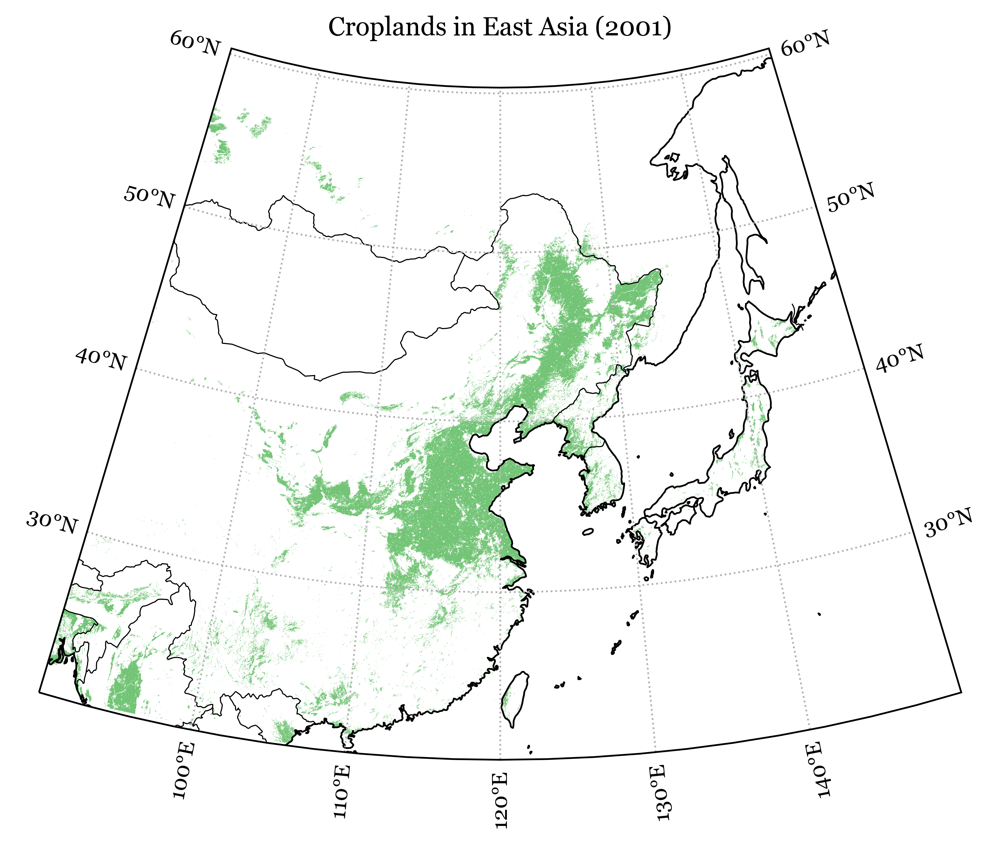

In [7]:
#| code-fold: true

# Create a figure with a map
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(1, 1, 1, projection=ccrs.AlbersEqualArea(central_longitude=120, central_latitude=40))
ax.set_extent([land_cover_2001_2020.x.min(), land_cover_2001_2020.x.max(),
               land_cover_2001_2020.y.min(), land_cover_2001_2020.y.max()],
               crs=ccrs.PlateCarree())


# Add coastlines and borders
borders = cfeature.NaturalEarthFeature(
                    category='cultural',
                    name='admin_0_boundary_lines_land',
                    scale='50m',
                    facecolor='none')

ax.add_feature(borders, linewidth=.5)
ax.coastlines(resolution='50m', linewidth=0.8)

# Plot the cropland data
(land_cover_2001_2020
 .where(land_cover_2001_2020==12)
 .sel(time='2001-01-01')
 ['LC_Type1']
 .plot
 .pcolormesh('x', 'y', ax=ax, transform=ccrs.PlateCarree(),
             cmap='Greens', add_colorbar=False)
)

xlim = land_cover_2001_2020.x.min(), land_cover_2001_2020.x.max()
ylim = land_cover_2001_2020.y.min(), land_cover_2001_2020.y.max()

rect = mpath.Path([[xlim[0], ylim[0]],
                   [xlim[1], ylim[0]],
                   [xlim[1], ylim[1]],
                   [xlim[0], ylim[1]],
                   [xlim[0], ylim[0]],
                   ]).interpolated(20)

proj_to_data = ccrs.PlateCarree()._as_mpl_transform(ax) - ax.transData
rect_in_target = proj_to_data.transform_path(rect)
ax.set_boundary(rect_in_target)
ax.set_extent([xlim[0], xlim[1], ylim[0] - 5, ylim[1]])

gl = ax.gridlines(draw_labels=True, linestyle=':')
gl.ylabel_style = {'size': 10}
gl.xlabel_style = {'size': 10}
gl.top_labels = False
gl.right_labels = False

# Show the plot
plt.title('Croplands in East Asia (2001)')
plt.show()


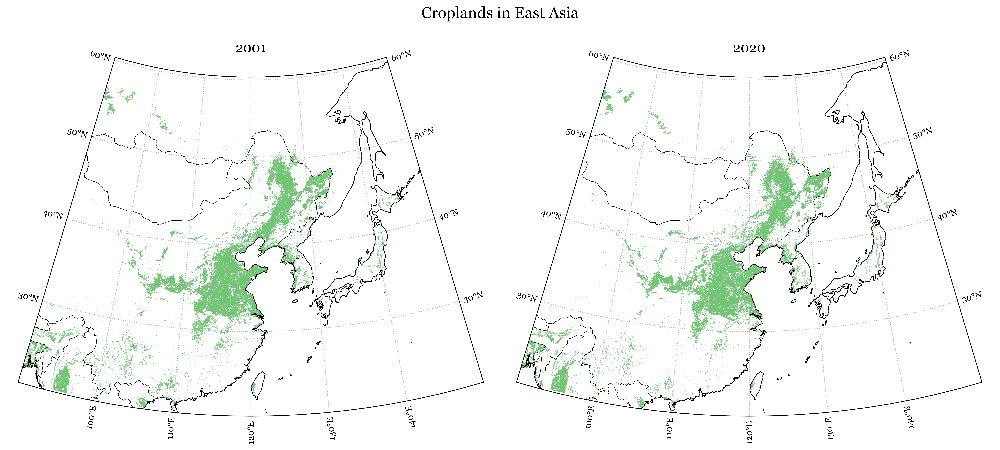

In [10]:
#| code-fold: true
#| column: page-inset

# Create a figure with two subplots side by side
fig, axs = plt.subplots(1, 2, figsize=(16, 8), subplot_kw={'projection': ccrs.AlbersEqualArea(central_longitude=120, central_latitude=40)})
    
for i, year in enumerate([2001, 2020]):
    axs[i].set_extent([land_cover_2001_2020.x.min(), land_cover_2001_2020.x.max(),
                     land_cover_2001_2020.y.min(), land_cover_2001_2020.y.max()],
                     crs=ccrs.PlateCarree())

    # Add coastlines and borders

    axs[i].add_feature(borders, linewidth=.5)
    axs[i].coastlines(resolution='50m', linewidth=0.8)

    (land_cover_2001_2020
     .where(land_cover_2001_2020==12)
     .sel(time=f'{year}-01-01')
     ['LC_Type1']
     .plot
     .pcolormesh('x', 'y', ax=axs[i], transform=ccrs.PlateCarree(),
                 cmap='Greens', add_colorbar=False)
    )

    proj_to_data = ccrs.PlateCarree()._as_mpl_transform(axs[i]) - axs[i].transData
    rect_in_target = proj_to_data.transform_path(rect)

    axs[i].set_boundary(rect_in_target)
    axs[i].set_extent([xlim[0], xlim[1], ylim[0] - 5, ylim[1]])
    gl = axs[i].gridlines(draw_labels=True, linestyle=':', )
    gl.top_labels = False
    gl.right_labels = False

    # Set the plot title
    axs[i].set_title(f'{year}', size=16)


# Show the plot
plt.tight_layout()
plt.suptitle('Croplands in East Asia', size=18)
plt.show()


In [6]:
# Define the cropland condition
is_cropland = land_cover_2001_2020['LC_Type1'] == 12

# Pixels that have been croplands for the entire period (2001-2020)
croplands_always = is_cropland.all(dim='time')

# Pixels that were croplands at 2001 but are not anymore
croplands_2001_not_now = is_cropland.sel(time='2001-01-01') & ~is_cropland.sel(time='2020-01-01')

# Pixels that were not croplands at 2001 but are now
not_croplands_2001_but_now = ~is_cropland.sel(time='2001-01-01') & is_cropland.sel(time='2020-01-01')

# Pixels that have been croplands at some point in the period (2001-2020) but not at the beginning or the end of the period
croplands_in_between = is_cropland.any(dim='time') & ~croplands_always & ~croplands_2001_not_now & ~not_croplands_2001_but_now

# Now you can use these boolean DataArrays to classify your pixels. For example:
classification = xr.Dataset({
    'always_croplands': croplands_always.astype(int),
    'croplands_2001_not_now': croplands_2001_not_now.astype(int),
    'not_croplands_2001_but_now': not_croplands_2001_but_now.astype(int),
    'croplands_in_between': croplands_in_between.astype(int)
})

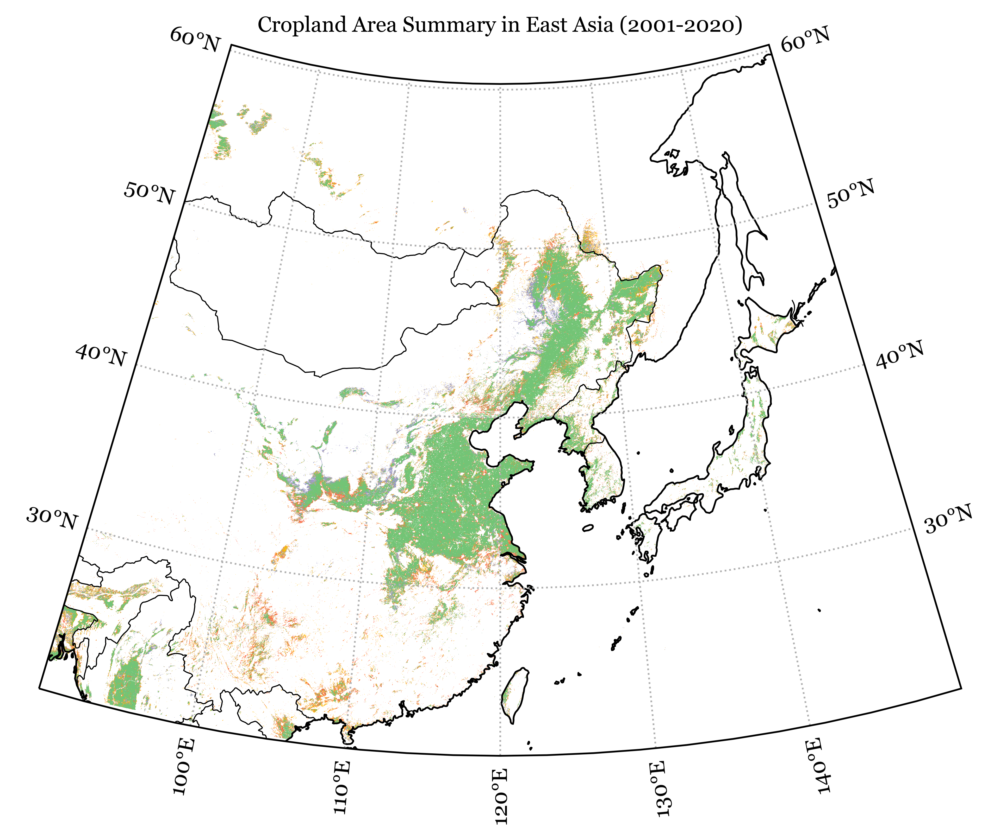

In [71]:
#| code-fold: true

category_colors = {
    'always_croplands': 'Greens',
    'croplands_2001_not_now': 'Reds',
    'not_croplands_2001_but_now': 'Purples',
    'croplands_in_between': 'Wistia',
}

# Create a figure with a map
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(1, 1, 1, projection=ccrs.AlbersEqualArea(central_longitude=120, central_latitude=40))
ax.set_extent([land_cover_2001_2020.x.min(), land_cover_2001_2020.x.max(),
               land_cover_2001_2020.y.min(), land_cover_2001_2020.y.max()],
               crs=ccrs.PlateCarree())
               
# Add coastlines and borders
borders = cfeature.NaturalEarthFeature(
                    category='cultural',
                    name='admin_0_boundary_lines_land',
                    scale='50m',
                    facecolor='none')

ax.add_feature(borders, linewidth=.5)
ax.coastlines(
    resolution='50m',
    linewidth=0.8
)

proj_to_data = ccrs.PlateCarree()._as_mpl_transform(ax) - ax.transData
rect_in_target = proj_to_data.transform_path(rect)

ax.set_boundary(rect_in_target)
ax.set_extent([xlim[0], xlim[1], ylim[0] - 5, ylim[1]])

# Plot each category
for category, color in category_colors.items():
    (classification[category]
     .where(lambda x: x == 1)
     .plot
     .pcolormesh('x', 'y', ax=ax, transform=ccrs.PlateCarree(), cmap=color, add_colorbar=False)
    )

# Add gridlines and labels
gl = ax.gridlines(draw_labels=True, linestyle=':', )
gl.top_labels = False
gl.right_labels = False
gl.ylabel_style = {'size': 10}
gl.xlabel_style = {'size': 10}

# Show the plot
plt.title('Cropland Area Summary in East Asia (2001-2020)', size=10)
plt.show()

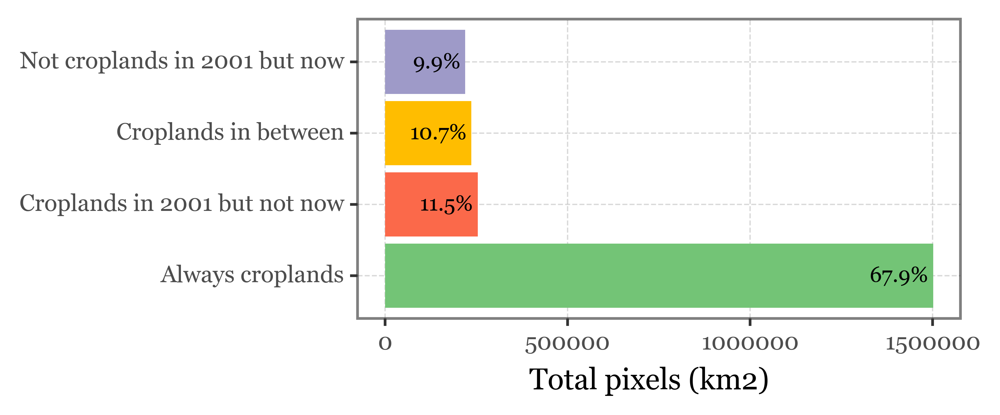

<ggplot: (673220251)>

In [9]:
#| code-fold: true

(classification.sum()
 .to_pandas()
 .rename('counts')
 .reset_index()
 .rename(columns={'index': 'category'})
 .replace({
        'always_croplands': 'Always croplands',
        'croplands_2001_not_now': 'Croplands in 2001 but not now',
        'not_croplands_2001_but_now': 'Not croplands in 2001 but now',
        'croplands_in_between': 'Croplands in between'
 }
 )
 .assign(fraction=lambda dd: dd['counts'] / dd['counts'].sum())
 .pipe(lambda dd: p9.ggplot(dd)
            + p9.aes('category', 'counts')
            + p9.geom_col(p9.aes(fill='category'))
            + p9.scale_fill_manual(values=['#73C476', '#FB694A', '#FFBD00', '#9E9AC8'])
            + p9.coord_flip()
            + p9.geom_text(p9.aes(
              label='(fraction.round(3) * 100).astype(str) + "%"',
              y='counts - 12500',
              ), size=8, ha='right')
            + p9.labs(x='', y='Total pixels (km2)')
            + p9.theme(figure_size=(4, 2))
            + p9.guides(fill=False)
            
 )
)

/var/folders/gm/58_ltb9x1yb9ndrlrf10jnbr0000gn/T/ipykernel_50007/19525139.py:12: UserWarning: FixedFormatter should only be used together with FixedLocator


''

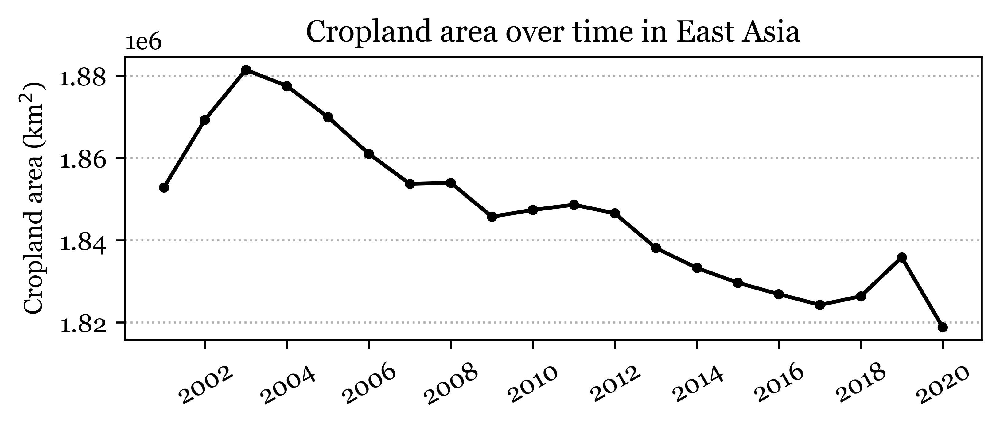

In [10]:
#| code-fold: true

fig, ax = plt.subplots(1, 1, figsize=(6, 2))
is_cropland.sum(dim=['x', 'y']).plot(
    marker='o', linestyle='-', color='k', markersize=3, ax=ax)

ax.set_ylabel('Cropland area (km$^2$)')
ax.set_xlabel('')
ax.set_title('Cropland area over time in East Asia')
ax.grid(axis='y', linestyle=':')
xlabels = ax.get_xlabel()
ax.set_xticklabels(range(2000, 2022, 2), ha='center')
;

/var/folders/gm/58_ltb9x1yb9ndrlrf10jnbr0000gn/T/ipykernel_50007/4119411135.py:12: UserWarning: FixedFormatter should only be used together with FixedLocator


''

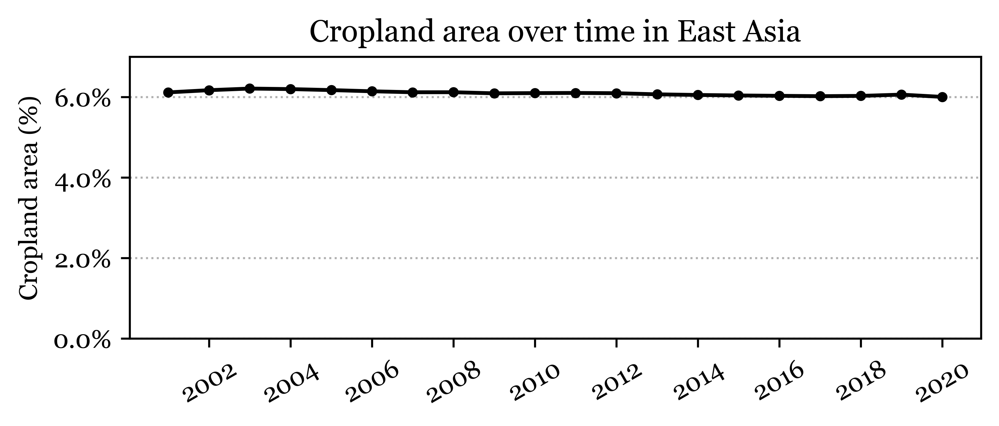

In [119]:
#| code-fold: true

fig, ax = plt.subplots(1, 1, figsize=(6, 2))
is_cropland.mean(dim=['x', 'y']).plot(
    marker='o', linestyle='-', color='k', markersize=3, ax=ax)

ax.set_ylabel('Cropland area (%)')
ax.set_xlabel('')
ax.set_title('Cropland area over time in East Asia')
ax.grid(axis='y', linestyle=':')
xlabels = ax.get_xlabel()
ax.set_xticklabels(range(2000, 2022, 2), ha='center')
# percent formatter
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_ylim(0, 0.07)
;

In [88]:
#| code-fold: true

crop_chunks_df = []
for lon in range(100, 150, 10):
    for lat in range(20, 60, 10):
        crop_chunks_df.append(is_cropland
    .sel(x=slice(lon, lon + 10), y=slice(lat, lat + 10))
    .mean(dim=['x', 'y'])
    .to_pandas()
    .rename('crop_fraction')
    .reset_index()
    .assign(lon=lon, lat=lat)
    .assign(lon_label=lambda dd: dd.lon.astype(str) + '-' + (dd.lon + 10).astype(str) + '°E')
    .assign(lat_label=lambda dd: dd.lat.astype(str) + '-' + (dd.lat + 10).astype(str) + '°N')

        )
        
crop_chunks_df = (pd.concat(crop_chunks_df)
    .assign(lat_label=lambda dd: pd.Categorical(dd.lat_label, categories=dd.lat_label.unique()[::-1], ordered=True))
)


/Users/alfontal/miniforge3/envs/kd-spatial-ts/lib/python3.10/site-packages/plotnine/geoms/geom_path.py:75: PlotnineWarning: geom_path: Removed 3 rows containing missing values.


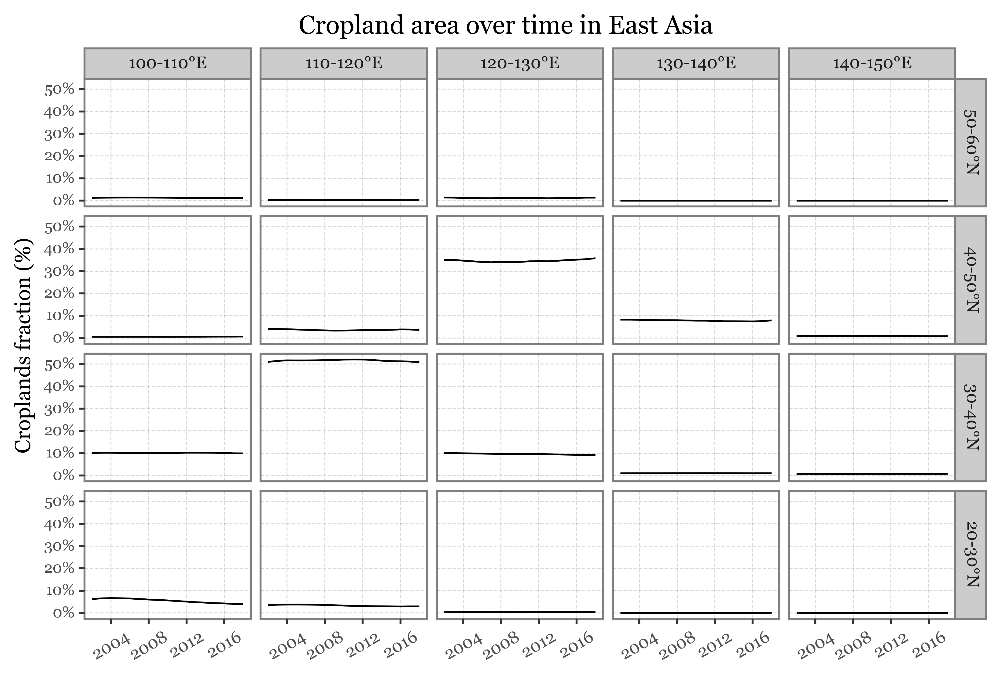

<ggplot: (798831166)>

In [120]:
#| code-fold: true

(crop_chunks_df
 .assign(crop_fraction=lambda dd: dd.crop_fraction.round(4))
 .pipe(lambda dd: p9.ggplot(dd)
    + p9.aes('time', 'crop_fraction')
    + p9.geom_line()
    + p9.scale_x_datetime(
         labels=date_format('%Y'),
         breaks=date_breaks('4 years'),
         limits=(pd.to_datetime('2002-01-01'), pd.to_datetime('2018-01-01'))
         )               
    + p9.scale_y_continuous(labels=percent_format())
    + p9.facet_grid('lat_label ~ lon_label')
    + p9.labs(x='', y='Croplands fraction (%)', 
              title='Cropland area over time in East Asia')
    + p9.theme(
      figure_size=(8, 5),
      axis_text_x=p9.element_text(rotation=30, ha='center'),
      axis_text_y=p9.element_text(size=8)
    )

 )
 )

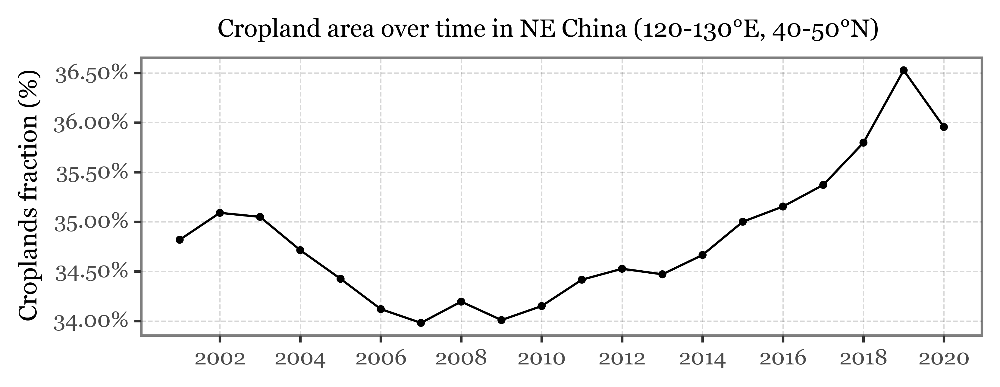

<ggplot: (798946686)>

In [142]:
#| code-fold: true

(crop_chunks_df
 .query('lon == 120 & lat == 40')
 .pipe(lambda dd: p9.ggplot(dd) 
    + p9.aes('time', 'crop_fraction') 
    + p9.geom_line()
    + p9.geom_point(size=.8)
    + p9.labs(x='', y='Croplands fraction (%)', title='Cropland area over time in NE China (120-130°E, 40-50°N)')
    + p9.scale_y_continuous(labels=percent_format())
    + p9.scale_x_datetime(labels=date_format('%Y'))
    + p9.theme(figure_size=(6, 2),
               title=p9.element_text(size=10)
    )       
 )
)